# Ac-225 Dual Photopeak Reconstruction

Two of Ac-225's daughters give photopeaks a gamma camera can use: Fr-221's 218 keV gamma and Bi-213's 440 keV gamma. Each peak holds only part of a scan's few counts, so this tutorial reconstructs one image from both, as the [multiple photopeaks tutorial](t_dualpeak.ipynb) does for Lu-177's two peaks, and compares it with each peak's own reconstruction.

Both peaks' PSFs come from [spectarf](https://github.com/stephenagraves/MCARF-to-PytomoPSF)'s angular response functions (ARFs) of the camera, as in [Ac-225 PSF modelling (DICOM)](t_ac225_dicom_recon.ipynb). Their kernels are absolute, the probability that an emitted photon is detected, so one model of the camera gives both the blur and the sensitivity at each peak. With the photons each decay emits, the two system matrices predict counts per decay of Ac-225, and one image explains both peaks without calibration factors.

It needs spectarf: `pip install "spectarf[pytomography]"`.

In [1]:
from pytomography import datasets

# The tutorial data: downloaded the first time it runs (see Tutorial data in the docs)
datasets.fetch("SPECT/Ac225-NEMA-SymT2")
DATA = datasets.data_dir()  # the PYTOMOGRAPHY_DATA folder, or ~/pytomography_data
# Results go here, never into the data folder
OUTPUT = datasets.output_dir("SPECT/Ac225-NEMA-SymT2")

SPECT/Ac225-NEMA-SymT2: already downloaded


In [2]:
import os
import time
import matplotlib.pyplot as plt
import numpy as np
import torch
from pytomography import io
from pytomography.projectors import ExtendedSystemMatrix
from pytomography.projectors.SPECT import SPECTSystemMatrix
from pytomography.algorithms import OSEM
from pytomography.likelihoods import PoissonLogLikelihood
from pytomography.transforms.SPECT import SPECTAttenuationTransform
from pytomography.transforms.shared import GaussianFilter
from pytomography.utils import plot_utils
from spectarf import Collimator, DetectorStack, DetectorResponse, EnergyResolution
from spectarf.nuclides import Nuclide
from spectarf.pytomography import generate_arfs, psf_at, psf_transform

In [3]:
path = DATA / 'SPECT' / 'Ac225-NEMA-SymT2'
files_CT = [os.path.join(path, 'CT', file) for file in os.listdir(path / 'CT')]
file_NM = os.path.join(path, 'projection_data.IMA')

`io.SPECT.read_dicom` reads all six energy windows: each photopeak, with a window on either side of it for its scatter estimate.

In [4]:
projections, object_meta, proj_meta = io.SPECT.read_dicom(file_NM)
windows = proj_meta.energy_windows
for i, window in enumerate(windows):
    print(f'Index {i}:   Name: "{window.name}", Energies: {window.lower_keV:.1f}-{window.upper_keV:.1f} keV, photon {window.photon_keV:g} keV')

Index 0:   Name: "Window Group A", Energies: 196.2-239.8 keV, photon 218 keV
Index 1:   Name: "Window Group B", Energies: 163.5-196.2 keV, photon 179.85 keV
Index 2:   Name: "Window Group C", Energies: 239.8-272.5 keV, photon 256.15 keV
Index 3:   Name: "Window Group D", Energies: 396.0-484.0 keV, photon 440 keV
Index 4:   Name: "Window Group E", Energies: 352.0-396.0 keV, photon 374 keV
Index 5:   Name: "Window Group F", Energies: 484.0-572.0 keV, photon 528 keV


The two photopeaks, each with its triple energy window (TEW) scatter estimate, smoothed as in the [DICOM tutorial](t_ac225_dicom_recon.ipynb):

In [5]:
photopeak218 = projections[0]
photopeak440 = projections[3]
scatter218 = io.SPECT.energy_window_scatter(projections, proj_meta, peak=0, lower=1, upper=2,
                                            sigma_theta=2, sigma_r_mm=4.8, sigma_z_mm=4.8)
scatter440 = io.SPECT.energy_window_scatter(projections, proj_meta, peak=3, lower=4, upper=5,
                                            sigma_theta=2, sigma_r_mm=4.8, sigma_z_mm=4.8)
for name, peak, scatter in [('218 keV', photopeak218, scatter218), ('440 keV', photopeak440, scatter440)]:
    print(f'{name}: {peak.sum():,.0f} counts, of which the scatter estimate is {scatter.sum() / peak.sum():.0%}')

218 keV: 185,849 counts, of which the scatter estimate is 90%
440 keV: 153,308 counts, of which the scatter estimate is 77%


## The camera

A Siemens Symbia T2 with its high energy collimator (SY-HE) and 3/8 inch of NaI(Tl), given by name as in the [DICOM tutorial](t_ac225_dicom_recon.ipynb). Every value is listed on the [SPECT parameters](../spect_parameters.md) page.

In [6]:
collimator = io.SPECT.collimator('SY-HE')            # the Symbia high energy collimator
detector = io.SPECT.detector('NaI-9.5mm')            # 3/8 inch NaI(Tl), its cover and backscatter
camera = io.SPECT.camera('Siemens Symbia T')          # energy resolution model and intrinsic resolution
stack = DetectorStack(Collimator(**collimator), **detector)
response = DetectorResponse(EnergyResolution.geb(**camera['energy_resolution']),
                            intrinsic_fwhm_mm_140=camera['intrinsic_fwhm_mm_140'])

## PSFs in counts per decay

spectarf simulates the camera's response at each photopeak's photon energy (about 1.5 minutes per peak on a GPU the first time; later runs read spectarf's cache). Each ARF is the detection probability per photon. Weighting it by the photons per decay of Ac-225, with its daughters in equilibrium (DDEP's data, which spectarf ships), makes the kernels counts per decay: 0.11 photons per decay at 218 keV, 0.26 at 440 keV. At 440 keV the kernels have a sharp core, the six arms of the photons that cross the septa, and a wide haze; the [ARF tutorial](t_arf_psf.ipynb) shows them.

The kernels' sums are the sensitivities, printed here in counts per second per MBq (cps/MBq) at 150 mm from the collimator, to compare with a calibration measured on your camera.

In [7]:
ac225 = Nuclide.from_ddep('Ac-225', chain='secular')   # Ac-225 and its daughters, in equilibrium

def photons_per_decay(photon_keV):
    return sum(line.yield_per_decay for line in ac225.lines if abs(line.energy_keV - photon_keV) < 0.5)

arfs218 = generate_arfs(stack, response, proj_meta, peak=0)
arfs440 = generate_arfs(stack, response, proj_meta, peak=3)
per_decay218 = [(arfs218['P'], photons_per_decay(windows[0].photon_keV))]   # (ARF, weight): counts per decay
per_decay440 = [(arfs440['P'], photons_per_decay(windows[3].photon_keV))]
for name, terms in [('218 keV', per_decay218), ('440 keV', per_decay440)]:
    cps_per_MBq = 1e6 * psf_at(terms, 150.0, pixel_mm=float(object_meta.dx), size_mm=600.0).sum()
    print(f'{name}: {terms[0][1]:.4f} photons per decay, {cps_per_MBq:.2f} cps/MBq')

218 keV: 0.1142 photons per decay, 8.53 cps/MBq


440 keV: 0.2610 photons per decay, 18.66 cps/MBq


## The system matrices

One per photopeak, each with the attenuation map at its photon energy and the PSF transform of its kernels (absolute, the default of `psf_transform`). `ExtendedSystemMatrix` stacks the two: one image projects to both photopeaks at once. The kernels already hold each peak's sensitivity, so neither is scaled. The measured photopeaks and their scatter estimates are stacked in the same order.

In [8]:
def system_matrix_for(peak, kernels_per_decay):
    attenuation_map = io.attenuation_map(files_CT, object_meta, energy_keV=windows[peak].photon_keV)
    return SPECTSystemMatrix(
        obj2obj_transforms=[SPECTAttenuationTransform(attenuation_map=attenuation_map),
                            psf_transform(kernels_per_decay)],
        proj2proj_transforms=[],
        object_meta=object_meta,
        proj_meta=proj_meta,
    )

system_matrix218 = system_matrix_for(0, per_decay218)
system_matrix440 = system_matrix_for(3, per_decay440)
system_matrix = ExtendedSystemMatrix(system_matrices=[system_matrix218, system_matrix440])
photopeak = torch.stack([photopeak218, photopeak440])
scatter = torch.stack([scatter218, scatter440])

## Reconstruct

Three reconstructions with the same OSEM, 100 iterations of 3 subsets as in the [DICOM tutorial](t_ac225_dicom_recon.ipynb): each photopeak alone, and both together. First, the memory the joint reconstruction needs (`estimate_memory`):

In [9]:
likelihoods = {
    '218 keV': PoissonLogLikelihood(system_matrix218, photopeak218, scatter218),
    '440 keV': PoissonLogLikelihood(system_matrix440, photopeak440, scatter440),
    '218 + 440 keV': PoissonLogLikelihood(system_matrix, photopeak, scatter),
}
print(OSEM(likelihoods['218 + 440 keV']).estimate_memory(n_subsets=3))

OSEM (ExtendedSystemMatrix): 3 subsets
Peak ~ 5.9 GB RAM, 2.4 GB GPU (on Windows, GPU memory counts as RAM too)
  held for the whole run: 0.00 GB RAM, 0.5 GB GPU (image 0.01 GPU, H_m^T 1 of 3 subsets 0.03 GPU, images of an update 0.03 GPU, rotation grids of every view (cached) 0.1 GPU, what the object transforms keep 0.2 GPU, system matrix 2: what it holds 0.2 GPU, projections (the data) 0.01 GPU, additive term 0.01 GPU)
  one subset at a time: 0.00 GB RAM, 0.1 GB GPU (projections of a subset: measured, expected, additive term, of ones, padded copy, for each of 2, kept and stacked 0.1 GPU, padded object, support and sum of a projection 0.1 GPU, projections of ones of all 2 (for H^T 1) 0.01 GPU)
  projector chunks: 0.00 GB RAM, 0.7 GB GPU (one view: rotated object and the transforms' temporaries 0.7 GPU)
  Python, CUDA, allocator: 3.5 GB RAM, 1.1 GB GPU (Python, PyTorch and CUDA 3.0 RAM, CUDA context and libraries on the GPU (outside PyTorch) 0.7 GPU, PyTorch's GPU cache (rounded and ke

In [10]:
recons = {}
for name, likelihood in likelihoods.items():
    start = time.perf_counter()
    recons[name] = OSEM(likelihood)(n_iters=100, n_subsets=3)
    print(f'{name}: {time.perf_counter() - start:.0f} s')

218 keV: 66 s


440 keV: 65 s


218 + 440 keV: 125 s


## Compare

Each image is in decays per voxel during one view, since the projections are counts and the system matrices counts per decay. Dividing by the time per view (kept in `proj_meta`) gives Bq, and by the voxel's volume Bq/mL; a 20 mm FWHM Gaussian filter smooths the images for display, as in the DICOM tutorial.

In [11]:
seconds = float(proj_meta.frame_duration_s[0])
voxel_mL = float(object_meta.dx * object_meta.dy * object_meta.dz) / 1000
Bq_per_mL = {name: recon / seconds / voxel_mL for name, recon in recons.items()}
smooth = GaussianFilter(20)  # FWHM in mm
smooth.configure(object_meta, proj_meta)
kBq_per_mL = {name: smooth(image) / 1000 for name, image in Bq_per_mL.items()}
for name, recon in recons.items():
    print(f'{name}: {recon.sum() / seconds / 1e6:.2f} MBq in the field of view')

218 keV: 1.68 MBq in the field of view
440 keV: 1.01 MBq in the field of view
218 + 440 keV: 1.07 MBq in the field of view


Axial slice 70, through the 60 mm sphere (upper left) and the 37 mm sphere (bottom), on the CT, all three on one colour scale. The dashed lines are where the profiles below run.

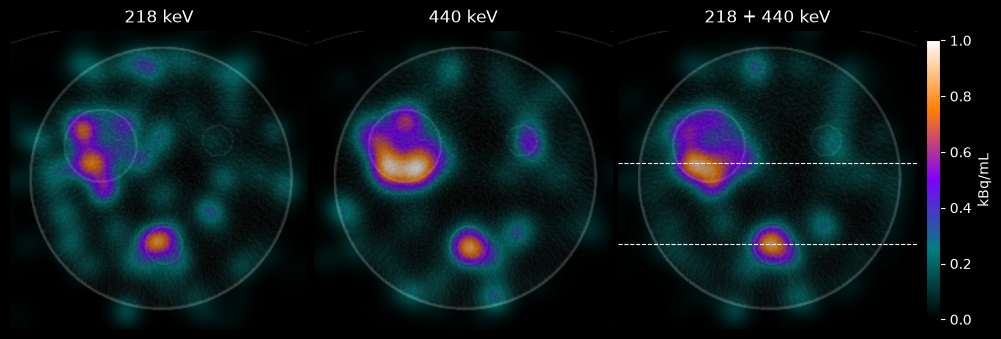

In [12]:
ct = io.load_image(files_CT)
SLICE = 70
ROWS = {'the 60 mm sphere': 82, 'the 37 mm sphere': 68}  # y indices of the profiles
VMAX = 1.0  # kBq/mL
affine = np.asarray(object_meta.affine)
spect_kwargs = {'cmap': plot_utils.pet_cmap, 'interpolation': 'gaussian', 'alpha': 0.7, 'vmin': 0, 'vmax': VMAX,
                'zorder': 1}
ct_kwargs = {'cmap': 'Greys_r', 'interpolation': 'gaussian', 'vmin': -25, 'vmax': 300, 'zorder': 0}
fig, axes = plt.subplots(1, 3, figsize=(12, 4.3), facecolor='k', gridspec_kw={'wspace': 0.02})
for ax, (name, image) in zip(axes, kBq_per_mL.items()):
    plt.sca(ax)
    plot_utils.dual_imshow_axial(image, ct.data, SLICE, object_meta.affine, ct.affine, spect_kwargs, ct_kwargs)
    ax.set(xlim=(-120, 130), ylim=(-275, -25))
    ax.axis('off')
    ax.set_title(name, color='white')
for row in ROWS.values():
    axes[-1].axhline(affine[1, 1] * row + affine[1, 3], color='white', lw=0.8, ls='--', zorder=2)
bar = fig.colorbar(plt.cm.ScalarMappable(plt.Normalize(0, VMAX), plot_utils.pet_cmap), ax=axes, fraction=0.015, pad=0.01)
bar.set_label('kBq/mL', color='white')
bar.ax.tick_params(colors='white')
plt.show()

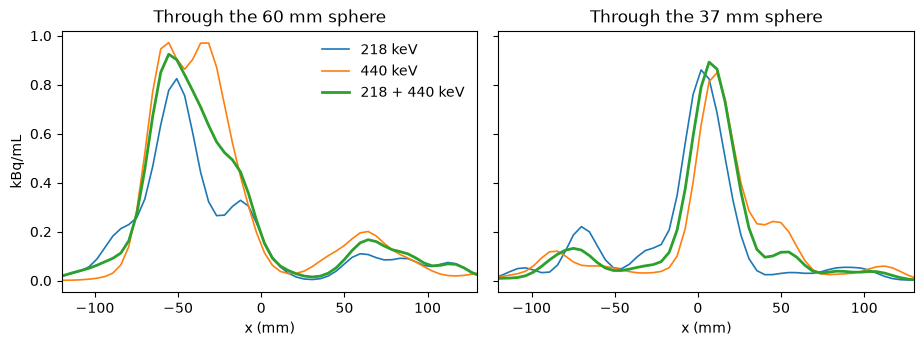

In [13]:
x_mm = affine[0, 0] * np.arange(object_meta.shape[0]) + affine[0, 3]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4), sharey=True, gridspec_kw={'wspace': 0.05})
for ax, (sphere, row) in zip(axes, ROWS.items()):
    for name, image in kBq_per_mL.items():
        ax.plot(x_mm, image[:, row, SLICE].cpu(), label=name, lw=2 if name == '218 + 440 keV' else 1.2)
    ax.set(title=f'Through {sphere}', xlabel='x (mm)', xlim=(-120, 130))
axes[0].set_ylabel('kBq/mL')
axes[0].legend(frameon=False)
plt.show()

The three agree on where the activity is, and roughly on how much is in the spheres. The 218 keV image alone is the noisiest, with the most activity in the background and the highest total in the field of view. Its window is 90% scatter, which makes it the most sensitive to two things. One is OSEM's positive bias at a few counts per pixel: an image can't be negative, so counts above the scatter estimate add activity while counts below it can't take any away. The other is any error in the scatter estimate itself. The joint image follows the 440 keV peak, which has twice the sensitivity and a smaller share of scatter; with the 218 keV counts added, its profiles are smoother than the 440 keV image's.

## Save the images

`io.save_dicom` writes each reconstruction as a DICOM nuclear medicine (NM) file in Bq/mL, in its place in the patient (`object_meta.affine`). `reference=file_NM` gives it the patient and study of the projections, so DICOM viewers show it with the scan's CT.

In [14]:
for (name, image), folder in zip(Bq_per_mL.items(), ['osem_218keV', 'osem_440keV', 'osem_joint']):
    io.save_dicom(image, OUTPUT / 't_ac225_dualpeak' / folder, object_meta, reference=file_NM, units='Bq/mL',
                  series_description=f'OSEM 100x3, {name}', overwrite=True)